In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '2_train_clean2.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_val_fe.parquet')

from sklearn import set_config
set_config(display='text')
# scikit-learn의 HTML 출력 과정에서 발생한 cp949 간 UTF-8 충돌 때문에 넣는 코드

In [2]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

target_col = 'target_maxrise_6h'  # 모델링 학습부터는 반드시 빼내야 함

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = wl_cols + rain_cols + env_cols
num_cols_fe_wl = num_cols + [
    col for col in wl_diff_cols if col != 'wl_t'
]
num_cols_fe = num_cols_fe_wl + [
    col for col in rain_int_cols if col not in ['imerg_rain_1h', 'sfc_rain_1h']
]

print(f"""<변수개수 검증>
    수위변수: {len(wl_cols)}
    강우변수: {len(rain_cols)}, 
    환경변수: {len(env_cols)}, 
    수위차분(wl_t포함): {len(wl_diff_cols)},
    강우강도(rain_1h포함): {len(rain_int_cols)}
    기존 숫자열(수위 + 강우 + 환경): {len(num_cols)}, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): {len(num_cols_fe_wl)},
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): {len(num_cols_fe)}
""")

<변수개수 검증>
    수위변수: 6
    강우변수: 9, 
    환경변수: 7, 
    수위차분(wl_t포함): 6,
    강우강도(rain_1h포함): 6
    기존 숫자열(수위 + 강우 + 환경): 22, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): 27,
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): 31



In [3]:
# ============================================================
# 2. 종속변수 설정
# ============================================================

y_train = train[target_col]
y_val = val[target_col]

In [4]:
# ============================================================
# 3. station_id 원핫인코딩 독립변수 생성
# ============================================================

# OHE 전 독립변수 데이터셋
X_train_fe = train[num_cols_fe]
X_val_fe = val[num_cols_fe]

# 원핫인코딩
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(
    handle_unknown='ignore',  # train에 없던 범주가 나와도 에러 X
    sparse_output=True  # sparse: 희소한, 희소행렬(0이 아닌 값이 드문 행렬)
    # 원핫인코딩 결과를 전체 다 저장 X, 희소한 1의 값의 위치만 저장(메모리 사용 적음)
)

# 학습은 train만
ohe.fit(train[['station_id']])  # sklearn 인코더는 2차원 행렬을 받는다.

# 변환
train_st_id_ohe = ohe.transform(train[['station_id']])
val_st_id_ohe = ohe.transform(val[['station_id']])
# 여기까지는 일반적은 인코딩 과정

# train, val 셋에 합치기
from scipy.sparse import hstack
# scipy안에 희소행렬을 다루는 서브캐키지 scipy.sparse
# hstack(horizontal stack)은 concat(axis=1)과 같은 역할, df가 아닌 행렬도 붙일 수 있는 함수

X_train_with_station_fe = hstack([
    X_train_fe,
    train_st_id_ohe
]).tocsr()  # df + 희소행력(ohe) -> csr형태로 저장하여 sparse 상태 유지
# 이 변수는 더이상 df가 아님

X_val_with_station_fe = hstack([
    X_val_fe,
    val_st_id_ohe
]).tocsr()

print("원핫인코딩 전 후 데이터셋 크기 비교: 행은 같고 열만 들어남")
print(X_train_fe.shape, X_train_with_station_fe.shape)
print(X_val_fe.shape, X_val_with_station_fe.shape)
# 제공된 데이터셋의 관측소 개수는 465개(md파일에 명시)
# 기존컬럼 31개 + 465 = 496이 정상

원핫인코딩 전 후 데이터셋 크기 비교: 행은 같고 열만 들어남
(616299, 31) (616299, 496)
(133325, 31) (133325, 496)


In [5]:
# ============================================================
# 4. 모델비교
# ============================================================

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models = {
    'LightGBM': LGBMRegressor(
        random_state = 42
    ),
    'XGBoost' : XGBRegressor(
    random_state = 42
    ),
    'CatBoost' : CatBoostRegressor(
    random_state = 42
    ),
}

# 학습, 예측, 평가
preds = {}  # 모델돌리는 셀과 정리하는 셀을 분리, 그러려면 결과들을 변수로 저장해야함
results = {}

for name, model in models.items():

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    results[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4)
    }


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.046708 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8757
[LightGBM] [Info] Number of data points in the train set: 616299, number of used features: 496
[LightGBM] [Info] Start training from score 0.111706
Learning rate set to 0.112971
0:	learn: 0.3821094	total: 230ms	remaining: 3m 49s
1:	learn: 0.3645451	total: 270ms	remaining: 2m 14s
2:	learn: 0.3497160	total: 310ms	remaining: 1m 42s
3:	learn: 0.3371944	total: 361ms	remaining: 1m 29s
4:	learn: 0.3266016	total: 407ms	remaining: 1m 20s
5:	learn: 0.3176704	total: 448ms	remaining: 1m 14s
6:	learn: 0.3096941	total: 494ms	remaining: 1m 10s
7:	learn: 0.3028641	total: 536ms	remaining: 1m 6s
8:	learn: 0.2972424	total: 574ms	remaining: 1m 3s
9:	learn: 0.2923176	total: 612ms	remaining: 1m
10:	learn: 0.2881155	total: 653ms	remaining: 58.7s
11:	learn: 0.2843557	total: 695ms	remaining: 57.2s
12:	learn: 0.2811024

{'LightGBM': {'pred_val': array([0.01017842, 0.00409229, 0.01355317, ..., 0.02104555, 0.01176096,
         0.008268  ], shape=(133325,)),
  'pred_train': array([0.01234823, 0.01460933, 0.03916634, ..., 0.19981231, 0.04993115,
         0.04959197], shape=(616299,))},
 'XGBoost': {'pred_val': array([ 0.00109452, -0.00853578,  0.00247149, ...,  0.0085077 ,
         -0.00332378, -0.00446234], shape=(133325,), dtype=float32),
  'pred_train': array([ 0.01053595, -0.0014991 ,  0.02231096, ...,  0.24059379,
          0.01811215,  0.03573906], shape=(616299,), dtype=float32)},
 'CatBoost': {'pred_val': array([ 0.01234131, -0.00725714, -0.00703593, ..., -0.00764899,
          0.0012635 , -0.00032954], shape=(133325,)),
  'pred_train': array([ 0.02197878, -0.00054608,  0.0155751 , ...,  0.24469715,
          0.0367024 ,  0.03774049], shape=(616299,))}}

            RMSE  RMSE_train     Gap
LightGBM  0.2021      0.2183 -0.0161
XGBoost   0.2006      0.1961  0.0045
CatBoost  0.1951      0.1935  0.0017



C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_4948\1120066594.py:103: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


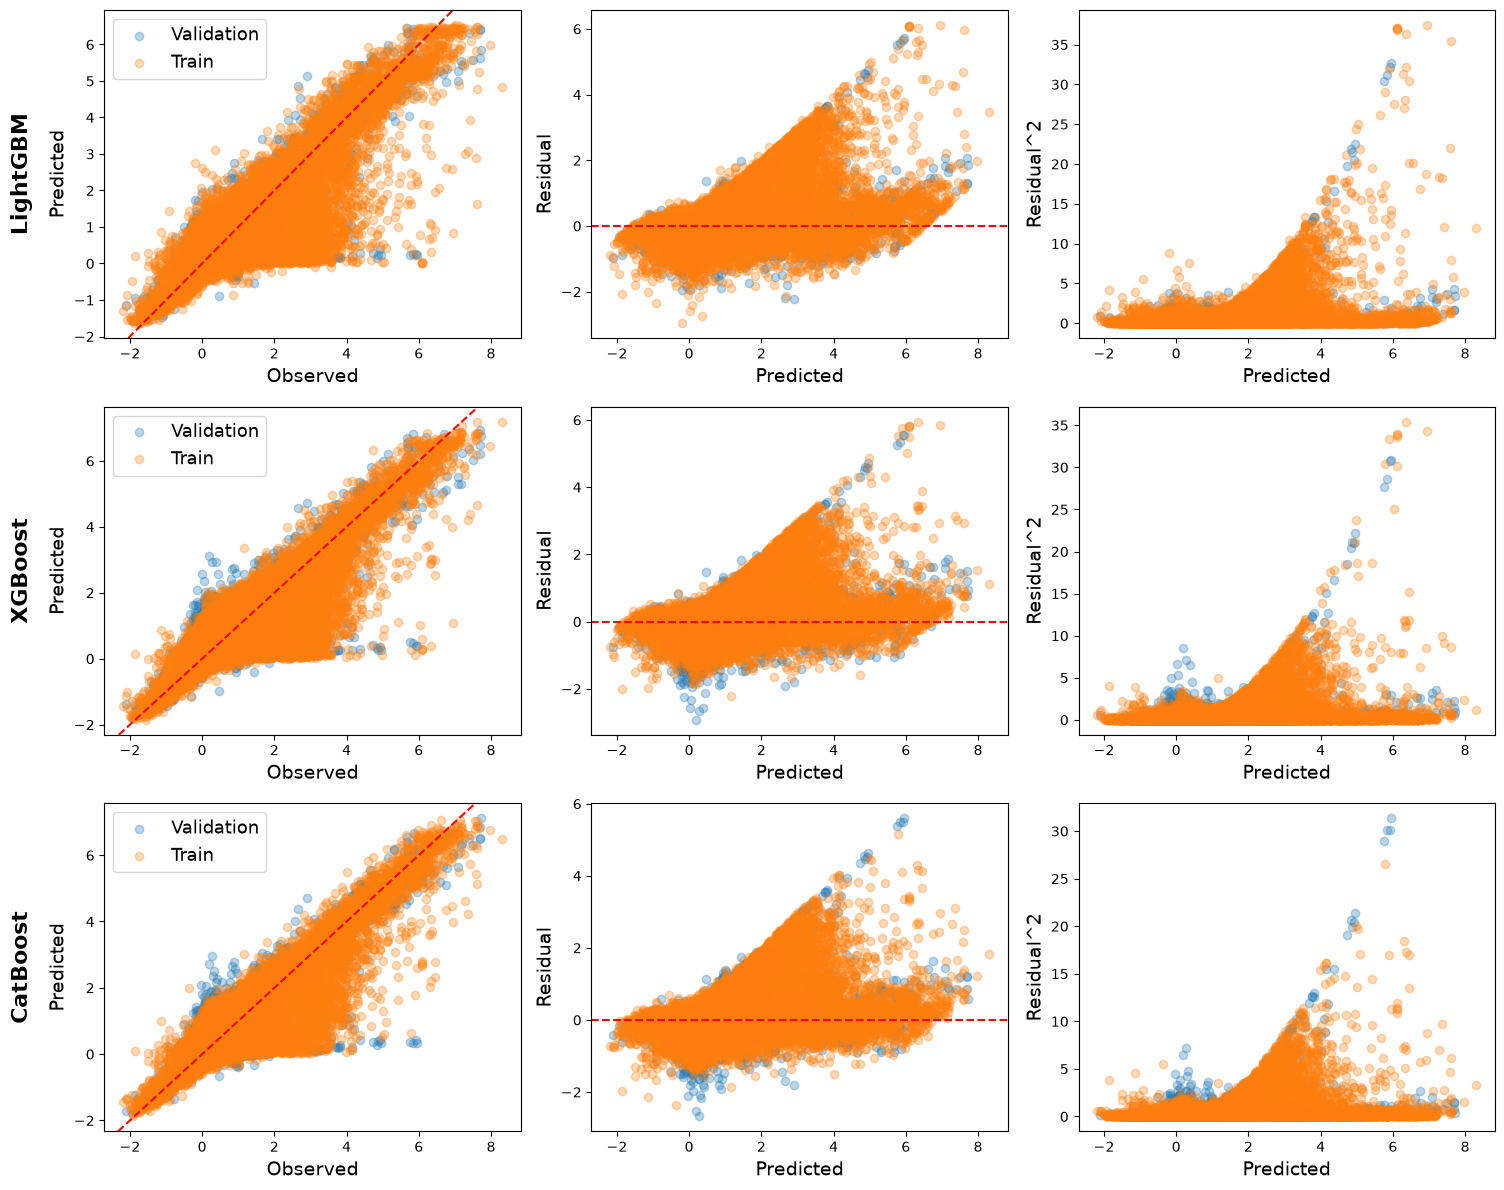

In [6]:
display(preds)
# display(results)

# rmse 비교표 만들기
result_df = pd.DataFrame.from_dict(
    results,
    orient='index',  # orient: orientation, 방향이라는 의미
    # 바깥 딕셔너리 키를 행인덱스로 보냄, 내부 딕셔너리 키는 자동으로 열인덱스로
    # 기본값은 orient='columns' 반대로 보냄
    # 그냥 없이 그려보고, 행열바꾸고 싶으면 넣으면 됨
)
print(result_df)
print()

# 모델별 val, train 예측값 플롯해보기: 각각 산점도, 오차 산점도, 오차제곱 산점도

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(preds),
    3,
    figsize = (15, 4 * len(preds))
)

if len(preds) == 1:
    axes = [axes]

for i, (name, pred) in enumerate(preds.items()):
    # preds.items()는 (외부 키, 내부 키 : 값) 형태임
    # 여기서 name은 외부 키, pred는 내부 딕셔너리 두개씩(pred_val, pred_train)
    # pred를 꺼내서 pred[]형태로 꺼내서 쓸 수 있음

    # 모델명: 각 행의 0열 그래프 왼쪽에 세로 표시
    axes[i][0].text(
        -0.2, 0.5,
        name,
        transform = axes[i][0].transAxes,
        rotation = 90,
        fontsize = 16,
        fontweight = 'bold',
        ha = 'center',
        va = 'center'
    )

    # 잔차 계산
    resid_val = y_val - pred['pred_val']
    resid_train = y_train - pred['pred_train']

    # 1열 그래프: 실제값 vs 예측값
    axes[i][0].scatter(
        y_val,
        pred['pred_val'],
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][0].scatter(
        y_train,
        pred['pred_train'],
        alpha = 0.3,
        label = 'Train'
    )
    axes[i][0].set_xlabel('Observed', fontsize = 14)
    axes[i][0].set_ylabel('Predicted', fontsize = 14)
    # 기준선: y=x
    axes[i][0].axline((0, 0), slope = 1, color = 'red', linestyle = '--')

    # 2열 그래프: 잔차
    axes[i][1].scatter(
        y_val,
        resid_val,
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][1].scatter(
        y_train,
        resid_train,
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][1].set_xlabel('Predicted', fontsize = 14)
    axes[i][1].set_ylabel('Residual', fontsize = 14)
    # 기준선 y=0
    axes[i][1].axhline(y = 0, color = 'red', linestyle = '--')

    # 3열 그래프: 잔차제곱
    axes[i][2].scatter(
        y_val,
        resid_val ** 2,
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][2].scatter(
        y_train,
        resid_train ** 2,
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][2].set_xlabel('Predicted', fontsize = 14)
    axes[i][2].set_ylabel('Residual^2', fontsize = 14)

    axes[i][0].legend(fontsize = 13)

plt.tight_layout()
plt.show()

In [7]:
# print(len(preds))

display(preds.items())

dict_items([('LightGBM', {'pred_val': array([0.01017842, 0.00409229, 0.01355317, ..., 0.02104555, 0.01176096,
       0.008268  ], shape=(133325,)), 'pred_train': array([0.01234823, 0.01460933, 0.03916634, ..., 0.19981231, 0.04993115,
       0.04959197], shape=(616299,))}), ('XGBoost', {'pred_val': array([ 0.00109452, -0.00853578,  0.00247149, ...,  0.0085077 ,
       -0.00332378, -0.00446234], shape=(133325,), dtype=float32), 'pred_train': array([ 0.01053595, -0.0014991 ,  0.02231096, ...,  0.24059379,
        0.01811215,  0.03573906], shape=(616299,), dtype=float32)}), ('CatBoost', {'pred_val': array([ 0.01234131, -0.00725714, -0.00703593, ..., -0.00764899,
        0.0012635 , -0.00032954], shape=(133325,)), 'pred_train': array([ 0.02197878, -0.00054608,  0.0155751 , ...,  0.24469715,
        0.0367024 ,  0.03774049], shape=(616299,))})])